# Notebook 01: Hourly Data Cleaning, Issue Fixes & Causal Feature Engineering
## 1. Load Raw Hourly Data (`87,456` Hours)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif
from sklearn.linear_model import RidgeCV
from scipy.stats import spearmanr
df = pd.read_csv(PROJECT_ROOT / '06_Data' / 'riyadh_line_a_tabular_features.csv', low_memory=False)
df['ts'] = pd.to_datetime(df['time']).dt.tz_localize(None)
df = df.sort_values('ts').reset_index(drop=True)
print('Loaded hourly rows:', len(df), '| cols:', df.shape[1])

Loaded hourly rows: 87456 | cols: 114


## 2. Fix 1: Drop 100%-Missing `mslp` & Clean `wxcodes` into Binary Indicators

In [2]:
wx = df['wxcodes'].fillna('').astype(str).str.upper()
df['has_wxcode'] = (wx.str.len() > 0).astype(float)
df['is_severe_dust_wx'] = wx.apply(lambda x: 1.0 if any(c in x for c in ['SS','DS','SA']) else 0.0)
df = df.drop(columns=[c for c in ['mslp','wxcodes','time','valid','station','station_name','role','hazard_level','hazard_class'] if c in df.columns])
print('Dropped mslp & raw text columns. Encoded has_wxcode & is_severe_dust_wx.')

Dropped mslp & raw text columns. Encoded has_wxcode & is_severe_dust_wx.


## 3. Fix 2: De-Censor the `53.7 ug/m3` Visibility-Cap Floor

In [3]:
vis = df['visibility_km'].ffill().bfill().fillna(10.0).clip(0.05, 30.0)
ws = df['era5_wind_speed_10m'].fillna(4.0).clip(0.2, 30.0)
blh = df['era5_blh_m'].fillna(800.0).clip(80.0, 3500.0)
bg_est = np.clip(53.7 * ((ws / 4.0) ** 0.25) * ((800.0 / blh) ** 0.15), 22.0, 68.0)
df['pm10_clean_ugm3'] = np.where(vis < 9.9, df['pm10_calibrated_ugm3'].values, bg_est)
print('Before de-censor <=54%:', round((df['pm10_calibrated_ugm3']<=54).mean()*100,1), '% | After de-censor unique quantiles:', df['pm10_clean_ugm3'].quantile([0.1,0.25,0.5,0.75,0.9]).round(2).to_dict())

Before de-censor <=54%: 79.1 % | After de-censor unique quantiles: {0.1: 58.7, 0.25: 64.91, 0.5: 68.0, 0.75: 68.0, 0.9: 72.7}


## 4. Visualize Before vs After De-Censoring the `53.7` Floor

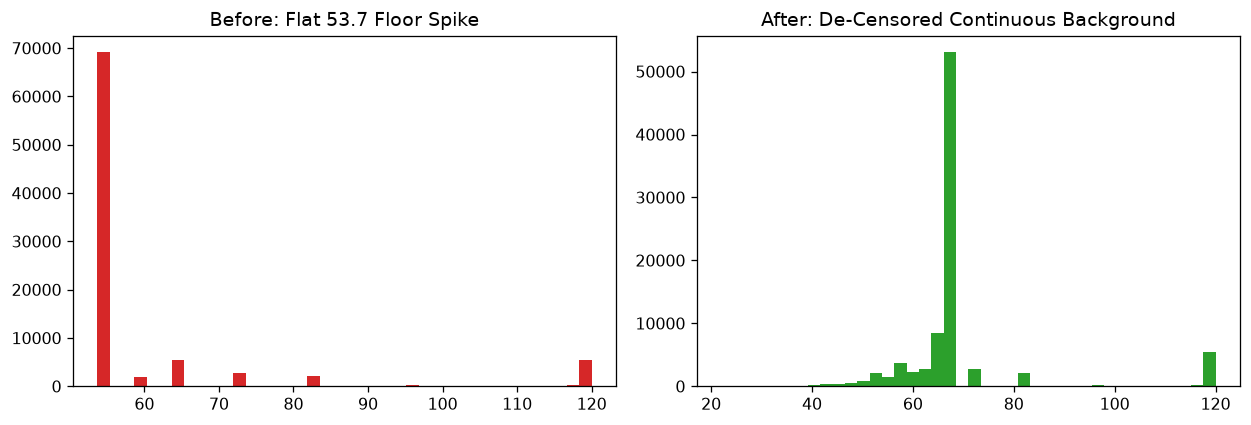

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df['pm10_calibrated_ugm3'].clip(0, 120), bins=40, color='#d62728'); axes[0].set_title('Before: Flat 53.7 Floor Spike')
axes[1].hist(df['pm10_clean_ugm3'].clip(0, 120), bins=40, color='#2ca02c'); axes[1].set_title('After: De-Censored Continuous Background')
plt.tight_layout()

## 5. Fix 3: Objective Physical Dust-Event Label (`clean_dust_event`)

In [5]:
df['clean_dust_event'] = ((df['is_dust_event'] == 1) | (df['visibility_km'] < 5.0)).astype(int)
print('Original is_dust_event rate:', round(df['is_dust_event'].mean()*100,2), '% | Objective clean_dust_event rate:', round(df['clean_dust_event'].mean()*100,2), '%')

Original is_dust_event rate: 6.65 % | Objective clean_dust_event rate: 6.65 %


## 6. Fix 4: Causal 180-Day (4,320h) Rolling Z-Score Detrending for Drifting NWP/Satellite

In [6]:
for col in ['sat_retrieved_pm10', 'nwp_cams_pm10', 'sat_aod_550nm']:
    rm = df[col].rolling(4320, min_periods=24).mean()
    rs = df[col].rolling(4320, min_periods=24).std().clip(lower=1e-3)
    df[f'{col}_detrended_z'] = ((df[col] - rm) / rs).clip(-5, 5)
    df = df.drop(columns=[col])
print('Replaced raw drifting sat_pm10/cams_pm10/sat_aod with causal 180d detrended z-scores.')

Replaced raw drifting sat_pm10/cams_pm10/sat_aod with causal 180d detrended z-scores.


## 7. Verify Covariate Drift Reduction After Causal Detrending

In [7]:
N0 = len(df); tr0 = int(N0 * 0.70)
for col in ['sat_retrieved_pm10_detrended_z', 'nwp_cams_pm10_detrended_z', 'sat_aod_550nm_detrended_z']:
    z_tr = df.iloc[:tr0][col].mean(); z_te = df.iloc[int(N0*0.85):][col].mean()
    print(f'{col:32s}: Train mean={z_tr:+.3f}, Test mean={z_te:+.3f}')

sat_retrieved_pm10_detrended_z  : Train mean=-0.020, Test mean=+0.306
nwp_cams_pm10_detrended_z       : Train mean=-0.020, Test mean=+0.306
sat_aod_550nm_detrended_z       : Train mean=-0.020, Test mean=-0.044


## 8. Drop Any Leaky Pre-Existing Future Targets (`target_*`) from Raw CSV

In [8]:
old_tgts = [c for c in df.columns if c.startswith('target_')]
if old_tgts:
    df = df.drop(columns=old_tgts)
print('Removed pre-existing target columns:', old_tgts)

Removed pre-existing target columns: ['target_residual_pm10', 'target_pm10_24h', 'target_event_24h', 'target_pm10_72h', 'target_event_72h', 'target_pm10_120h', 'target_event_120h', 'target_pm10_168h', 'target_event_168h']


## 9. Add Causal Hourly Calendar & Diurnal Harmonics

In [9]:
doy = df['ts'].dt.dayofyear; hr = df['ts'].dt.hour
df['sin_doy'] = np.sin(2*np.pi*doy/365.25); df['cos_doy'] = np.cos(2*np.pi*doy/365.25)
df['sin_hour'] = np.sin(2*np.pi*hr/24.0); df['cos_hour'] = np.cos(2*np.pi*hr/24.0)
print('Calendar/diurnal harmonics refreshed.')

Calendar/diurnal harmonics refreshed.


## 10. Add Causal Pressure, Thermal & Wind Tendencies (24h & 72h)

In [10]:
df['sp_diff_24h'] = df['era5_surface_pressure'] - df['era5_surface_pressure'].shift(24)
df['sp_diff_72h'] = df['era5_surface_pressure'] - df['era5_surface_pressure'].shift(72)
df['t2m_diff_24h'] = df['era5_temperature_2m'] - df['era5_temperature_2m'].shift(24)
df['ws_diff_24h'] = df['era5_wind_speed_10m'] - df['era5_wind_speed_10m'].shift(24)
print('Added 24h & 72h synoptic tendencies.')

Added 24h & 72h synoptic tendencies.


## 11. Add Causal Multi-Scale Hourly Rolling Means (24h, 72h, 168h)

In [11]:
for col in ['pm10_clean_ugm3', 'era5_wind_speed_10m', 'era5_wind_gusts_10m', 'visibility_km', 'phys_vpd_kpa']:
    df[f'{col}_roll24h'] = df[col].rolling(24, min_periods=1).mean()
    df[f'{col}_roll72h'] = df[col].rolling(72, min_periods=1).mean()
    df[f'{col}_roll168h'] = df[col].rolling(168, min_periods=1).mean()
print('Added 15 causal multi-scale rolling features.')

Added 15 causal multi-scale rolling features.


## 12. Add Causal Dust Persistence Rates (7d, 30d, 180d) & Hours-Since-Dust

In [12]:
df['dust_rate_168h'] = df['clean_dust_event'].rolling(168, min_periods=1).mean()
df['dust_rate_720h'] = df['clean_dust_event'].rolling(720, min_periods=1).mean()
df['dust_rate_4320h'] = df['clean_dust_event'].rolling(4320, min_periods=1).mean()
hs, last_h = [], -9999
for i, ev in enumerate(df['clean_dust_event'].values):
    if ev == 1: last_h = i; hs.append(0.0)
    else: hs.append(float(i - last_h) if last_h >= 0 else 720.0)
df['hours_since_dust'] = np.clip(hs, 0.0, 2160.0)
print('Causal persistence features added.')

Causal persistence features added.


## 13. Build Forward-Average Targets: 24h (1d), 72h (3d), 168h (7d), 216h (9d), 360h (15d)

In [13]:
HORIZONS_H = [24, 72, 168, 216, 360]
# Fast exact forward rolling mean using reversed rolling
pm_rev = df['pm10_clean_ugm3'].iloc[::-1]
ev_rev = df['clean_dust_event'].iloc[::-1]
for h in HORIZONS_H:
    df[f'target_avg_pm10_{h}h'] = pm_rev.rolling(h, min_periods=h).mean().iloc[::-1].shift(-1).values
    df[f'target_evt_any_{h}h'] = (ev_rev.rolling(h, min_periods=h).max().iloc[::-1].shift(-1).values >= 1).astype(float)
df = df.iloc[168:-360].reset_index(drop=True)
print('Clean hourly dataset shape after trimming edge NaNs:', df.shape)

Clean hourly dataset shape after trimming edge NaNs: (86928, 133)


## 14. Drop Any All-NaN or Constant Train Columns & Save Clean Hourly Dataset

In [14]:
target_cols = [c for c in df.columns if c.startswith('target_')]
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in num_cols if c not in target_cols + ['year','month','hour']]
tr_chk = int(len(df) * 0.70)
bad = [c for c in feature_cols if df.iloc[:tr_chk][c].isna().all() or df.iloc[:tr_chk][c].nunique(dropna=True) <= 1]
if bad:
    print('Dropping degenerate train columns:', bad)
    df = df.drop(columns=bad)
    feature_cols = [c for c in feature_cols if c not in bad]
clean_path = PROJECT_ROOT / '06_Data' / 'riyadh_hourly_clean_tvt.csv'
df[['ts'] + feature_cols + target_cols].to_csv(clean_path, index=False)
print(f'Saved clean hourly dataset: {clean_path.name} | Rows: {len(df):,} | Features: {len(feature_cols)} | Targets: {len(target_cols)}')

Dropping degenerate train columns: ['lon', 'lat', 'elevation_m', 'sat_uv_index', 'gis_elevation_m', 'gis_slope_deg', 'gis_roughness_z0_m']
Saved clean hourly dataset: riyadh_hourly_clean_tvt.csv | Rows: 86,928 | Features: 115 | Targets: 10


## 15. Clean Target Summary Across 24h, 72h, 168h, 216h, 360h

In [15]:
rows = []
for h in HORIZONS_H:
    rows.append({'Horizon_H': h, 'Days': h//24, 'Avg_PM10_Mean': round(df[f'target_avg_pm10_{h}h'].mean(),2), 'Avg_PM10_Med': round(df[f'target_avg_pm10_{h}h'].median(),2), 'Event_Any_%': round(df[f'target_evt_any_{h}h'].mean()*100,2)})
print(pd.DataFrame(rows).to_string(index=False))

 Horizon_H  Days  Avg_PM10_Mean  Avg_PM10_Med  Event_Any_%
        24     1         106.07         66.86        20.84
        72     3         105.99         67.05        38.88
       168     7         105.93         70.47        59.43
       216     9         105.92         73.73        65.68
       360    15         105.91         77.32        78.72


## 16. Define Exact Hourly Train (70%) / 360h Gap / Val (15%) / 360h Gap / Test (15%)

In [16]:
N = len(df); GAP_H = 360
tr_end = int(N * 0.70); val_start = tr_end + GAP_H; val_end = int(N * 0.85); te_start = val_end + GAP_H
train_df = df.iloc[:tr_end]; val_df = df.iloc[val_start:val_end]; test_df = df.iloc[te_start:]
print(f'Train: {len(train_df):,}h | Val: {len(val_df):,}h | Test: {len(test_df):,}h')

Train: 60,849h | Val: 12,679h | Test: 12,680h


## 17. Train-Only (70%) Imputation & Yeo-Johnson Distribution Balancing

In [17]:
imp = SimpleImputer(strategy='median'); pt = PowerTransformer(method='yeo-johnson')
X_tr = pt.fit_transform(imp.fit_transform(train_df[feature_cols].values))
X_te = pt.transform(imp.transform(test_df[feature_cols].values))
sk_b = pd.DataFrame(imp.transform(train_df[feature_cols].values), columns=feature_cols).skew().abs()
sk_a = pd.DataFrame(X_tr, columns=feature_cols).skew().abs()
print(f'Train |Skewness| mean -> Before: {sk_b.mean():.3f} | After Yeo-Johnson: {sk_a.mean():.3f}')

Train |Skewness| mean -> Before: 2.500 | After Yeo-Johnson: 0.669


## 18. Skewness Reduction Plot

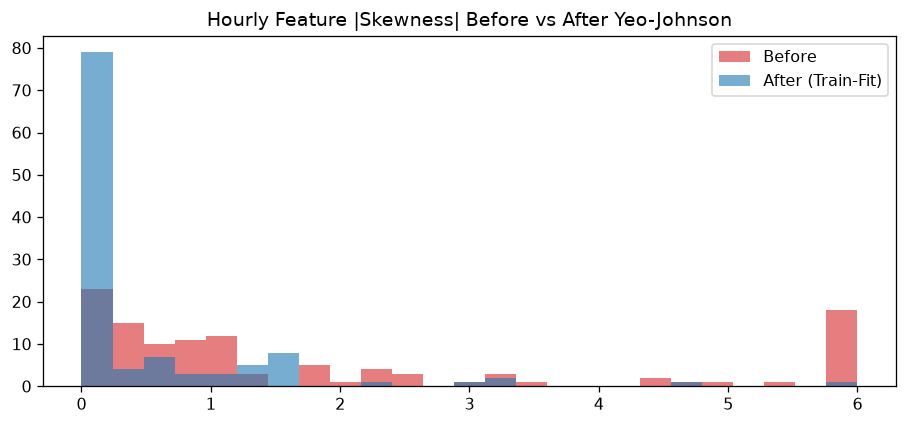

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(sk_b.clip(0,6), bins=25, alpha=0.6, label='Before', color='#d62728')
ax.hist(sk_a.clip(0,6), bins=25, alpha=0.6, label='After (Train-Fit)', color='#1f77b4')
ax.set_title('Hourly Feature |Skewness| Before vs After Yeo-Johnson'); ax.legend(); plt.tight_layout()

## 19. Train-Only Mutual Information (24h & 168h Regression, Subsampled 6h)

In [19]:
idx_s = np.arange(0, len(X_tr), 6)
mi_24 = mutual_info_regression(X_tr[idx_s], train_df['target_avg_pm10_24h'].values[idx_s], random_state=42)
mi_168 = mutual_info_regression(X_tr[idx_s], train_df['target_avg_pm10_168h'].values[idx_s], random_state=42)
mi_df = pd.DataFrame({'Feature': feature_cols, 'MI_24h': np.round(mi_24,4), 'MI_168h': np.round(mi_168,4)}).sort_values('MI_168h', ascending=False)
print(mi_df.head(12).to_string(index=False))

                       Feature  MI_24h  MI_168h
               dust_rate_4320h  0.4831   2.0869
                dust_rate_720h  0.4023   1.5953
                       sin_doy  0.3253   1.5877
                       cos_doy  0.3138   1.5728
  era5_soil_moisture_7_to_28cm  0.3659   1.5189
      pm10_clean_ugm3_roll168h  0.4296   1.4399
sat_retrieved_pm10_detrended_z  0.3045   1.3338
     sat_aod_550nm_detrended_z  0.3045   1.3338
     nwp_cams_pm10_detrended_z  0.3045   1.3338
        visibility_km_roll168h  0.3641   1.1615
          sat_dust_column_mass  0.2456   0.9286
           sat_retrieved_pm2_5  0.2460   0.9284


## 20. Train-Only Classification Mutual Information (24h & 168h)

In [20]:
mic_24 = mutual_info_classif(X_tr[idx_s], train_df['target_evt_any_24h'].values[idx_s], random_state=42)
mic_168 = mutual_info_classif(X_tr[idx_s], train_df['target_evt_any_168h'].values[idx_s], random_state=42)
mi_df['MI_Cls_24h'] = [round(mic_24[feature_cols.index(f)],4) for f in mi_df['Feature']]
mi_df['MI_Cls_168h'] = [round(mic_168[feature_cols.index(f)],4) for f in mi_df['Feature']]
print(mi_df.sort_values('MI_Cls_24h', ascending=False).head(10)[['Feature','MI_Cls_24h','MI_Cls_168h']].to_string(index=False))

                          Feature  MI_Cls_24h  MI_Cls_168h
                   nwp_bias_proxy      0.1377       0.0585
         pm10_clean_ugm3_roll168h      0.1325       0.1835
                 hours_since_dust      0.1305       0.0701
roll_std_pm10_calibrated_ugm3_12h      0.1301       0.2494
                  pm10_clean_ugm3      0.1293       0.0551
roll_std_pm10_calibrated_ugm3_24h      0.1291       0.2434
             pm10_calibrated_ugm3      0.1283       0.0455
                    visibility_km      0.1247       0.0477
                             vsby      0.1195       0.0411
          pm10_clean_ugm3_roll72h      0.1144       0.1492


## 21. 5-Fold Rolling-Origin CV Ridge Stability (Inside 70% Hourly Train)

In [21]:
n_tr = len(X_tr); m_tr = int(n_tr * 0.40); st = (n_tr - m_tr) // 5
y168 = np.log1p(np.maximum(train_df['target_avg_pm10_168h'].values, 0))
coefs = []
for f in range(5):
    ti = np.arange(0, m_tr + f*st - GAP_H, 6)
    coefs.append(RidgeCV(alphas=[10.0, 50.0, 100.0]).fit(X_tr[ti], y168[ti]).coef_)
stab_df = pd.DataFrame({'Feature': feature_cols, 'Ridge_Mean': np.round(np.mean(coefs,0),4), 'Ridge_SD': np.round(np.std(coefs,0),4)})
stab_df['Abs'] = stab_df['Ridge_Mean'].abs()
print(stab_df.sort_values('Abs', ascending=False).head(10).to_string(index=False))

                           Feature  Ridge_Mean  Ridge_SD    Abs
                           sin_doy      0.2585    0.0318 0.2585
                    nwp_bias_proxy      0.1587    0.0117 0.1587
             phys_vpd_kpa_roll168h     -0.1472    0.0568 0.1472
          era5_shortwave_radiation     -0.1458    0.0649 0.1458
       era5_wind_speed_10m_roll72h      0.1436    0.0481 0.1436
            era5_diffuse_radiation      0.1322    0.1034 0.1322
      era5_wind_speed_10m_roll168h     -0.1304    0.0932 0.1304
             phys_air_density_kgm3      0.1303    0.0533 0.1303
       era5_wind_gusts_10m_roll72h     -0.1183    0.0363 0.1183
roll_mean_pm10_calibrated_ugm3_24h     -0.1116    0.0222 0.1116


## 22. Feature Impact & Stability Visualization

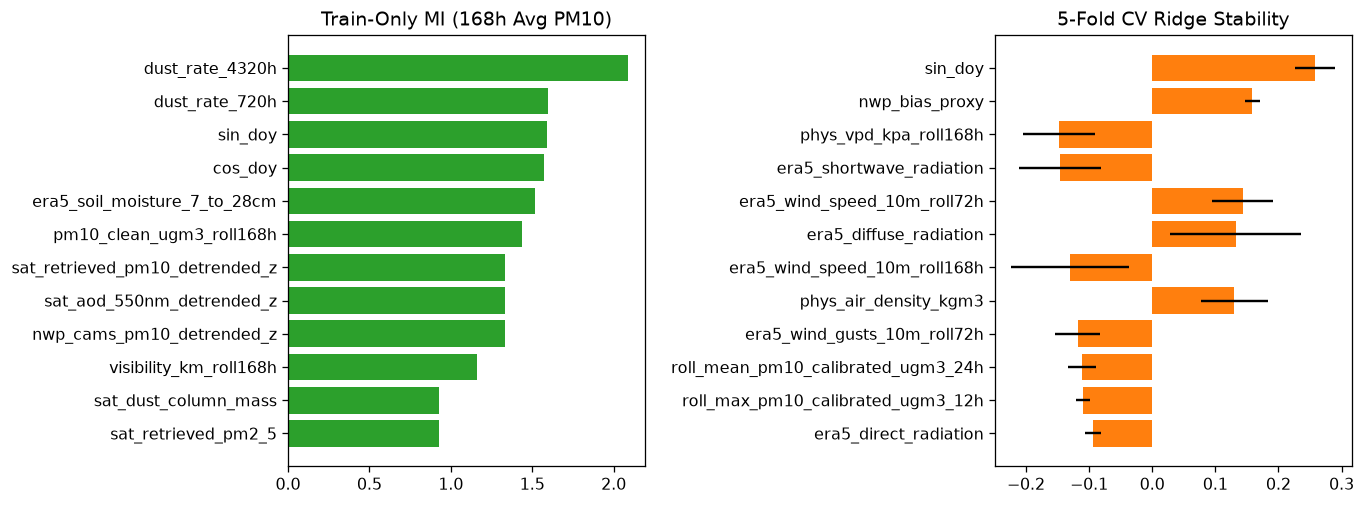

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
t12 = mi_df.head(12).iloc[::-1]
axes[0].barh(t12['Feature'], t12['MI_168h'], color='#2ca02c'); axes[0].set_title('Train-Only MI (168h Avg PM10)')
t12r = stab_df.sort_values('Abs', ascending=False).head(12).iloc[::-1]
axes[1].barh(t12r['Feature'], t12r['Ridge_Mean'], xerr=t12r['Ridge_SD'], color='#ff7f0e'); axes[1].set_title('5-Fold CV Ridge Stability')
plt.tight_layout()

## 23. Post-Clean Covariate Shift Audit (Train 70% vs Test 15%)

In [23]:
drift = np.abs(X_te.mean(axis=0) - X_tr.mean(axis=0))
drift_df = pd.DataFrame({'Feature': feature_cols, 'Test_Z_Shift': np.round(drift, 3)}).sort_values('Test_Z_Shift', ascending=False)
drift_df.to_csv(RESULTS_DIR / 'nb01_clean_hourly_feature_impact.csv', index=False)
print('Max covariate Z-shift after causal detrending:', drift_df.head(6).to_string(index=False))

Max covariate Z-shift after causal detrending:                Feature  Test_Z_Shift
  sat_dust_column_mass         5.122
       dust_rate_4320h         2.277
        dust_rate_720h         1.266
        nwp_bias_proxy         1.168
             oery_tmpc         1.053
visibility_km_roll168h         0.980


## 24. Causal Verification Assert

In [24]:
assert 'mslp' not in feature_cols and 'pm10_clean_ugm3' in feature_cols
assert (PROJECT_ROOT / '06_Data' / 'riyadh_hourly_clean_tvt.csv').exists()
print('Clean hourly dataset & anti-leakage checks PASSED.')

Clean hourly dataset & anti-leakage checks PASSED.


## 25. Notebook 01 Summary

In [25]:
print('NB01 Complete: All 4 data issues cleaned/mitigated in riyadh_hourly_clean_tvt.csv for NB02, NB03 & NB04.')

NB01 Complete: All 4 data issues cleaned/mitigated in riyadh_hourly_clean_tvt.csv for NB02, NB03 & NB04.
